# Introduction to Logistic Regression

In this notebook you will see how logistic regression works very graphically. 

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix


Next, we’ll take advantage of the `make_classification` function from the scikit-learn library to generate data. 
Since logistic regression is primarily only applicable to binary classification problems, the data points in our case are composed of two classes.

In [2]:
# We set a random state so the generated data is the same for each run of this cell
x, y = make_classification(
    n_samples=100,
    n_features=1,
    n_classes=2,
    n_clusters_per_class=1,
    flip_y=0.03,
    n_informative=1,
    n_redundant=0,
    n_repeated=0,
    random_state=3789,
)

In [3]:
data = {"x": x.reshape((100,)), "y": y.reshape((100,))}

In [4]:
df = pd.DataFrame(data=data)
df

,x,y
0,1.071387,1
1,1.637385,1
2,0.946752,1
3,2.302251,1
4,0.528806,1
...,...,...
95,-1.414146,0
96,1.119315,1
97,-1.354310,0
98,0.547361,1


In [5]:
# statistical properties for each class y (0,1)
statistical_properties_for_class = df.groupby(by=["y"])[["x"]].describe()
statistical_properties_for_class

x                                                                      
  count      mean       std       min       25%       50%       75%       max
y                                                                            
0  51.0 -0.807349  0.969754 -2.607748 -1.430320 -0.778034 -0.236799  2.057215
1  49.0  0.891327  0.544230 -0.476926  0.542125  0.965722  1.169664  2.302251

Text(0.5, 1.0, 'Binary Classification Data')

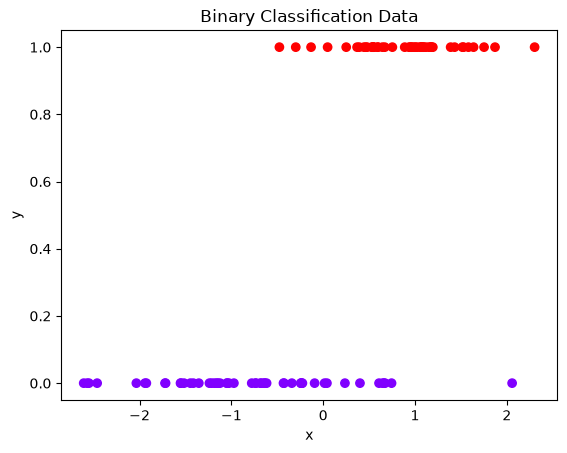

In [6]:
# We plot the relationship between the feature and classes.
plt.scatter(x, y, c=y, cmap="rainbow")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Binary Classification Data")

The above depicts a graph of a binary classification dataset.  The y-axis represents the true class labels for each data point. In this dataset, y = 0 likely represents the negative class and y=1 represents the positive class. The x-axis,  depicts one variable.
For observation belonging to the negative class (y=0) x ranges from -2.6 and 2.03, and for observation belonging to the positive class (y=1) x ranges from -0.48 and 2.30. Check statistical_properties_for_class python variable for more statistical information.

In [7]:
# Prior to training our model, we’ll set aside a portion of our data in order to evaluate its performance.
X_train, X_test, y_train, y_test = train_test_split(x, y, random_state=1)

In [8]:
# We instantiate an instance of the LogisticRegression class and call the fit function with the features and the labels
# (since Logistic Regression is a supervised machine learning algorithm) as arguments.

lr = LogisticRegression()
lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [9]:
# We can access the following properties to actually view the model parameter.
print(lr.coef_)
print(lr.intercept_)

[[2.17670904]]
[-0.05053172]


In [10]:
# Let’s see how the model performs against data that it hasn’t been trained on.
y_pred = lr.predict(X_test)

In [11]:
# Given that this is a classification problem, we use a confusion matrix to evaluate our model.
confusion_matrix(y_test, y_pred)

array([[12,  4],
       [ 0,  9]])

In [12]:
# If for whatever reason we’d like to check the actual probability that a data point belongs to a given class,
# we can use the predict_proba function.
lr.predict_proba(X_test)

array([[0.98583006, 0.01416994],
       [0.1722633 , 0.8277367 ],
       [0.92936602, 0.07063398],
       [0.13216349, 0.86783651],
       [0.68868327, 0.31131673],
       [0.16950854, 0.83049146],
       [0.99632678, 0.00367322],
       [0.9781116 , 0.0218884 ],
       [0.89724063, 0.10275937],
       [0.97782194, 0.02217806],
       [0.63749593, 0.36250407],
       [0.20427251, 0.79572749],
       [0.10820081, 0.89179919],
       [0.8240724 , 0.1759276 ],
       [0.0325385 , 0.9674615 ],
       [0.07544301, 0.92455699],
       [0.30556617, 0.69443383],
       [0.19569622, 0.80430378],
       [0.04877346, 0.95122654],
       [0.24489648, 0.75510352],
       [0.11812855, 0.88187145],
       [0.50429387, 0.49570613],
       [0.95250498, 0.04749502],
       [0.0364039 , 0.9635961 ],
       [0.98626217, 0.01373783]])

In [13]:
pd.DataFrame(lr.predict_proba(X_test))

,0,1
0,0.985830,0.014170
1,0.172263,0.827737
2,0.929366,0.070634
3,0.132163,0.867837
4,0.688683,0.311317
5,0.169509,0.830491
6,0.996327,0.003673
7,0.978112,0.021888
8,0.897241,0.102759
9,0.977822,0.022178


The first column corresponds to the probability that the sample belongs to the first class (our case y=0) and the second column corresponds to the probability that the sample belongs to the second class (our case y=1).

Before attempting to plot the Sigmoid function (it gives the probability that a certain observation belongs to the positive class), we create and sort a DataFrame containing our test data.

In [14]:
df = pd.DataFrame({"x": X_test[:, 0], "y": y_test})
df = df.sort_values(by="x")

In [15]:
df

,x,y
6,-2.550857,0
24,-1.940194,0
0,-1.925765,0
7,-1.722387,0
9,-1.716211,0
22,-1.354310,0
2,-1.160679,0
8,-0.972295,0
13,-0.686198,0
4,-0.341543,0


In [16]:
from scipy.special import expit

sigmoid_function = expit(df["x"] * lr.coef_[0][0] + lr.intercept_[0]).to_numpy()

The sigmoid function reads:
$$\sigma = \dfrac{1}{1+e^{-t}} =  \dfrac{1}{1+e^{-(b_{0} + b_{1}*X)}}$$

where:
- $\sigma$ is the predicted probability that the observation belongs to the positive class (y=1).
- $t$ is the linear combination of the input features, calculated as $b_{0} + b_{1}*X$, where $b_{0}$ is the intercept and $b_{1}$ is the coefficient for the feature $X$.

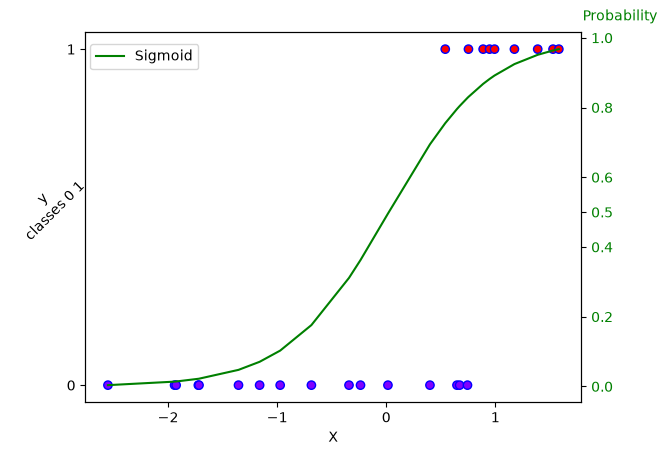

In [17]:
fig, ax = plt.subplots(sharey=True)

# Plot binary classification data
ax.scatter(df["x"], df["y"], c=df["y"], cmap="rainbow", edgecolors="b")
ax.tick_params(axis="y")
ax.set_xlabel("X")
ax.set_ylabel("y\nclasses 0 1", rotation=45)
ax.set_yticks([0.0, 1.0])

# Generate a new Axes instance, on the twin-X axes (same position)
ax2 = ax.twinx()

# Plot sigmoid function, change tick color
ax2.plot(df["x"], sigmoid_function, color="green", label="Sigmoid")
ax2.tick_params(axis="y", labelcolor="green")
ax2.set_yticks(np.insert(ax2.get_yticks()[1:-1], 3, 0.5))
ax2.text(x=1.8, y=1.05, s="Probability", color="Green")

ax2.legend(loc=(0.01, 0.9))
plt.show()

The above depicts a graph of a binary classification dataset.  The y-axis represents the true class labels for each data point. In this dataset, y = 0 likely represents the negative class and y=1 represents the positive class. The x-axis,  depicts one variable.
For observation belonging to the negative class (y=0) x ranges from -2.55 and 0.74 showed with blue dots, and for observation belonging to the positive class (y=1) x ranges from 0.54 and 1.58 and showed by red dots. There is a green line representing the sigmoid function which in y = 0.5 (threshold) has the x = $-b_0/b_1 = 0.023...$. there are 4 blue dots which have x larger than this value.

**Check your understanding:**
- Which value of X correspond to a probability threshold of 0.5?

<details>
<summary>Show answer</summary>

The sigmoid returns exactly 0.5 where the linear term is zero, that is where `b0 + b1*x = 0`, so `x = -b0/b1`. With this model's fitted coefficients that point is about `x = 0.023`. To the right of it the predicted probability is above 0.5 (class 1) and to the left it is below 0.5 (class 0), so this x value is the decision boundary for a 0.5 threshold.
</details>

- How many data points will be misclassified in the graph above if you choose a probability threshold at 0.5?

<details>
<summary>Show answer</summary>

Four. At the 0.5 threshold the boundary sits at `x = 0.023`, so every point with x greater than that is predicted as class 1. Four of the true class-0 points (the blue dots) lie to the right of the boundary, so they are predicted positive and counted as misclassified (false positives). The true class-1 points all fall on the correct side here.
</details>

- Which threshold would you choose to improve the accuracy?

<details>
<summary>Show answer</summary>

Accuracy improves when fewer points overall land on the wrong side of the boundary. Here the errors are class-0 points sitting just past `x = 0.023`, so raising the threshold (which shifts the boundary to the right, past those blue dots toward about x = 0.74) reclassifies them correctly and lifts accuracy. The trade-off is that pushing the boundary too far right starts turning true positives into false negatives, so you pick the threshold that minimises total errors, not just one kind.
</details>

- Which threshold would you choose to improve recall?

<details>
<summary>Show answer</summary>

Recall is the share of actual positives the model catches, TP / (TP + FN), so it improves when the model predicts class 1 more readily. That means lowering the threshold below 0.5, which moves the boundary left and labels more points positive, reducing false negatives. The cost is more false positives, so recall and precision pull against each other as you change the threshold.
</details>
